Original Training shape: (1200000, 2)
Original Evaluation shape: (89814, 2)

After Cleaning:
Training: (1200000, 2)
Evaluation: (89814, 2)

Duplicate Evaluation Texts Removed: 0
Evaluation after Deduplication: (89814, 2)

Training Texts Removed Due to Leakage: 0
Training after Leakage Removal: (1200000, 2)

Training Label Distribution:
label
recommended        400000
no_idea            400000
not_recommended    400000
Name: count, dtype: int64

Evaluation Label Distribution:
label
recommended        35502
no_idea            31871
not_recommended    22441
Name: count, dtype: int64

Classes:
['no_idea', 'not_recommended', 'recommended']

Final Dataset Sizes:
Training: 1200000
Validation: 44907
Test: 44907

Fitting TF-IDF...

TF-IDF Shapes:
Train: (1200000, 200000)
Validation: (44907, 200000)
Test: (44907, 200000)

Number of Features: 200000

Training Logistic Regression...
Training Completed.

Validation Results
Accuracy:          0.6696
Macro Precision:   0.6653
Macro Recall:      0.681

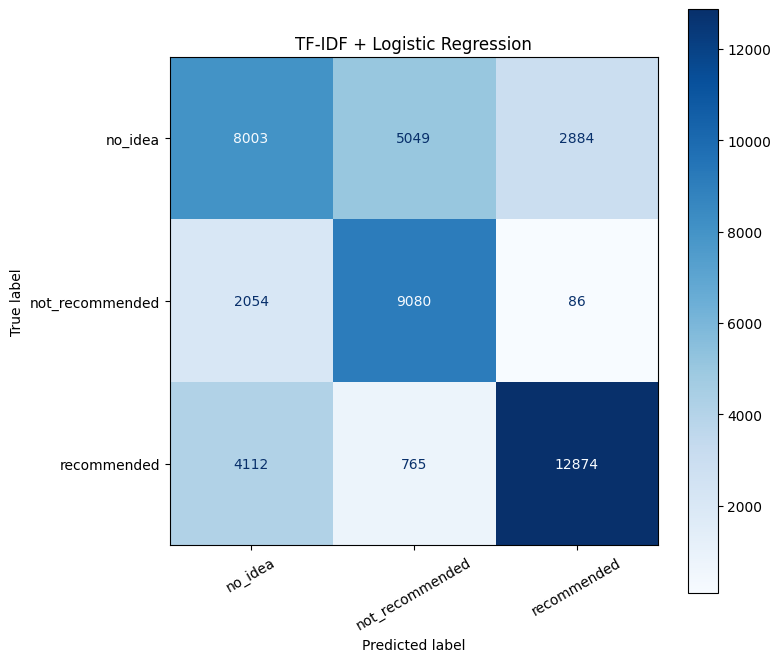


Metrics:
              dataset  accuracy  macro_precision  macro_recall  macro_f1  \
0  Validation Results  0.669584         0.665273      0.681719  0.667482   
1        Test Results  0.667090         0.662338      0.678907  0.664503   

   balanced_accuracy  
0           0.681719  
1           0.678907  

All files saved in: ./baseline_recommendation


In [2]:

# ============================================
# 1. Imports
# ============================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================
# 2. Configuration
# ============================================

TRAIN_PATH = "./digikala_1200k_cluster_sample_rate.csv"
EVAL_PATH = "./test_not_mismatch.csv"

OUTPUT_DIR = "./baseline_recommendation"

RANDOM_STATE = 42

MAX_FEATURES = 200000
MIN_DF = 2
MAX_DF = 0.95

NGRAM_RANGE = (1, 2)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================
# 3. Load Data
# ============================================

train_df = pd.read_csv(
    TRAIN_PATH,
    usecols=[
        "text",
        "recommendation_status_clean"
    ]
)

eval_df = pd.read_csv(
    EVAL_PATH,
    usecols=[
        "text",
        "recommendation_status"
    ]
)

print("Original Training shape:", train_df.shape)
print("Original Evaluation shape:", eval_df.shape)


# ============================================
# 4. Rename Columns
# ============================================

train_df = train_df.rename(
    columns={
        "recommendation_status_clean": "label"
    }
)

eval_df = eval_df.rename(
    columns={
        "recommendation_status": "label"
    }
)


# ============================================
# 5. Clean Data
# ============================================

def clean_dataframe(df):

    df = df.copy()

    df["text"] = (
        df["text"]
        .fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    df["label"] = (
        df["label"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[
        (df["text"] != "") &
        (df["label"] != "")
    ].copy()

    return df.reset_index(drop=True)


train_df = clean_dataframe(train_df)
eval_df = clean_dataframe(eval_df)

print("\nAfter Cleaning:")
print("Training:", train_df.shape)
print("Evaluation:", eval_df.shape)


# ============================================
# 6. Remove Duplicate Evaluation Texts
# ============================================

before = len(eval_df)

eval_df = eval_df.drop_duplicates(
    subset=["text"]
).reset_index(drop=True)

print("\nDuplicate Evaluation Texts Removed:", before - len(eval_df))
print("Evaluation after Deduplication:", eval_df.shape)


# ============================================
# 7. Remove Exact Text Leakage
# ============================================

eval_texts = set(eval_df["text"])

before = len(train_df)

train_df = train_df[
    ~train_df["text"].isin(eval_texts)
].copy()

train_df = train_df.reset_index(drop=True)

print("\nTraining Texts Removed Due to Leakage:", before - len(train_df))
print("Training after Leakage Removal:", train_df.shape)


# ============================================
# 8. Check Label Distribution
# ============================================

print("\nTraining Label Distribution:")
print(train_df["label"].value_counts())

print("\nEvaluation Label Distribution:")
print(eval_df["label"].value_counts())


# ============================================
# 9. Encode Labels
# ============================================

label_encoder = LabelEncoder()

train_df["label_id"] = label_encoder.fit_transform(
    train_df["label"]
)

class_names = label_encoder.classes_.tolist()

print("\nClasses:")
print(class_names)

unknown_labels = (
    set(eval_df["label"].unique()) -
    set(class_names)
)

if unknown_labels:
    raise ValueError(
        f"Unknown labels in evaluation data: {unknown_labels}"
    )

eval_df["label_id"] = label_encoder.transform(
    eval_df["label"]
)


# ============================================
# 10. Split Evaluation into Validation and Test
# ============================================

validation_df, test_df = train_test_split(
    eval_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=eval_df["label_id"]
)

validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nFinal Dataset Sizes:")
print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))


# ============================================
# 11. Prepare Text and Labels
# ============================================

X_train_text = train_df["text"]
y_train = train_df["label_id"]

X_val_text = validation_df["text"]
y_val = validation_df["label_id"]

X_test_text = test_df["text"]
y_test = test_df["label_id"]


# ============================================
# 12. TF-IDF Vectorization
# ============================================

tfidf = TfidfVectorizer(
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    ngram_range=NGRAM_RANGE,
    sublinear_tf=True,
    dtype=np.float32
)

print("\nFitting TF-IDF...")

X_train = tfidf.fit_transform(X_train_text)

X_val = tfidf.transform(X_val_text)

X_test = tfidf.transform(X_test_text)

print("\nTF-IDF Shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nNumber of Features:", len(tfidf.get_feature_names_out()))


# ============================================
# 13. Train Logistic Regression
# ============================================

model = LogisticRegression(
    C=4.0,
    max_iter=1000,
    solver="saga",
    n_jobs=-1,
    tol=1e-3,
    random_state=RANDOM_STATE
)

print("\nTraining Logistic Regression...")

model.fit(X_train, y_train)

print("Training Completed.")


# ============================================
# 14. Evaluation Function
# ============================================

def evaluate_model(model, X, y, dataset_name):

    predictions = model.predict(X)

    accuracy = accuracy_score(y, predictions)

    precision = precision_score(
        y,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y,
        predictions,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y,
        predictions
    )

    print("\n" + "=" * 55)
    print(dataset_name)
    print("=" * 55)

    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Macro Precision:   {precision:.4f}")
    print(f"Macro Recall:      {recall:.4f}")
    print(f"Macro F1:          {macro_f1:.4f}")
    print(f"Balanced Accuracy: {balanced_acc:.4f}")

    report = classification_report(
        y,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    )

    print("\nClassification Report:\n")
    print(report)

    results = {
        "dataset": dataset_name,
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "balanced_accuracy": balanced_acc
    }

    return predictions, results


# ============================================
# 15. Validation Evaluation
# ============================================

val_predictions, val_results = evaluate_model(
    model,
    X_val,
    y_val,
    "Validation Results"
)


# ============================================
# 16. Test Evaluation
# ============================================

test_predictions, test_results = evaluate_model(
    model,
    X_test,
    y_test,
    "Test Results"
)


# ============================================
# 17. Confusion Matrix
# ============================================

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names))
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30
)

plt.title("TF-IDF + Logistic Regression")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300
)

plt.show()


# ============================================
# 18. Save Confusion Matrix
# ============================================

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv"),
    encoding="utf-8-sig"
)


# ============================================
# 19. Save Classification Report
# ============================================

report_dict = classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv"),
    encoding="utf-8-sig"
)


# ============================================
# 20. Save Metrics
# ============================================

metrics_df = pd.DataFrame([
    val_results,
    test_results
])

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "metrics.csv"),
    index=False
)

print("\nMetrics:")
print(metrics_df)


# ============================================
# 21. Save Model and TF-IDF
# ============================================

joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "logistic_regression.pkl")
)

joblib.dump(
    tfidf,
    os.path.join(OUTPUT_DIR, "tfidf_vectorizer.pkl")
)

joblib.dump(
    label_encoder,
    os.path.join(OUTPUT_DIR, "label_encoder.pkl")
)


# ============================================
# 22. Save Experiment Manifest
# ============================================

manifest = {
    "task": "Recommendation Status Classification",
    "model": "TF-IDF + Logistic Regression",
    "training_file": TRAIN_PATH,
    "evaluation_file": EVAL_PATH,
    "classes": class_names,
    "random_state": RANDOM_STATE,
    "validation_test_split": "50/50",
    "cleaning": {
        "remove_empty_text": True,
        "remove_empty_labels": True,
        "normalize_whitespace": True,
        "remove_duplicate_evaluation_texts": True,
        "remove_train_eval_text_overlap": True
    },
    "tfidf": {
        "max_features": MAX_FEATURES,
        "min_df": MIN_DF,
        "max_df": MAX_DF,
        "ngram_range": list(NGRAM_RANGE),
        "sublinear_tf": True,
        "dtype": "float32"
    },
    "logistic_regression": {
        "C": 4.0,
        "max_iter": 1000,
        "solver": "saga",
        "tol": 1e-3
    },
    "dataset_sizes": {
        "train": len(train_df),
        "validation": len(validation_df),
        "test": len(test_df)
    },
    "validation_metrics": val_results,
    "test_metrics": test_results
}

with open(
    os.path.join(OUTPUT_DIR, "manifest.json"),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        ensure_ascii=False,
        indent=4
    )


print("\nAll files saved in:", OUTPUT_DIR)
